# Cubic subpixel PSF evaluation

Can fitting a point-spread function once save repeated model-evaluation work? This example measures that tradeoff with PCAT's direct `PointSpreadFunction` and fitted `CubicSubpixelPSF` implementations.

The synthetic workload uses identical double-King profiles across 3 or 16 energy bins and two quality classes. Pixels subtend 0.01 degree. Core and tail width parameters are two and four pixels, their King slopes are 2.4 and 2.0, and the mixture parameter is 0.82. A 21-by-21 grid defines the coefficient table, while each evaluation selects an 81-pixel cutout. We use 600 random subpixel shifts from a stated seed and report median evaluation times over three repeats. These profiles are computational test cases rather than measured instrument responses.

The fitted image evaluator uses all ten monomials of total degree at most three in the source's two subpixel shifts. Interleaved phase samples check density errors against 0.1 percent of the profile peak. Cells that fail that sampled check, out-of-table positions, and negative or nonfinite polynomial values use direct evaluation. Values are neither clipped nor renormalized. The sampled check does not provide a uniform error or likelihood-error bound.

The table separates construction cost from repeated evaluation cost. The speed ratio is direct time divided by fitted time, so values above one favor fitted evaluation after setup. Machine load and workload change these timings. PSF changes require rebuilding coefficients, and large image spans increase memory cost. Neither agreement of kernel values nor a kernel speedup establishes posterior equivalence or end-to-end sampler acceleration. Native Cartesian sampling selects this optional path with `kernevaltype="bspx"`; direct `"ulip"` remains the default.

,energy_bins,setup_seconds,direct_seconds,cubic_seconds,evaluation_speed_ratio,maximum_error_over_peak
0,3,0.16781,0.06508,0.05821,1.11807,0.00048
1,16,0.51135,0.16391,0.04417,3.71063,0.00048


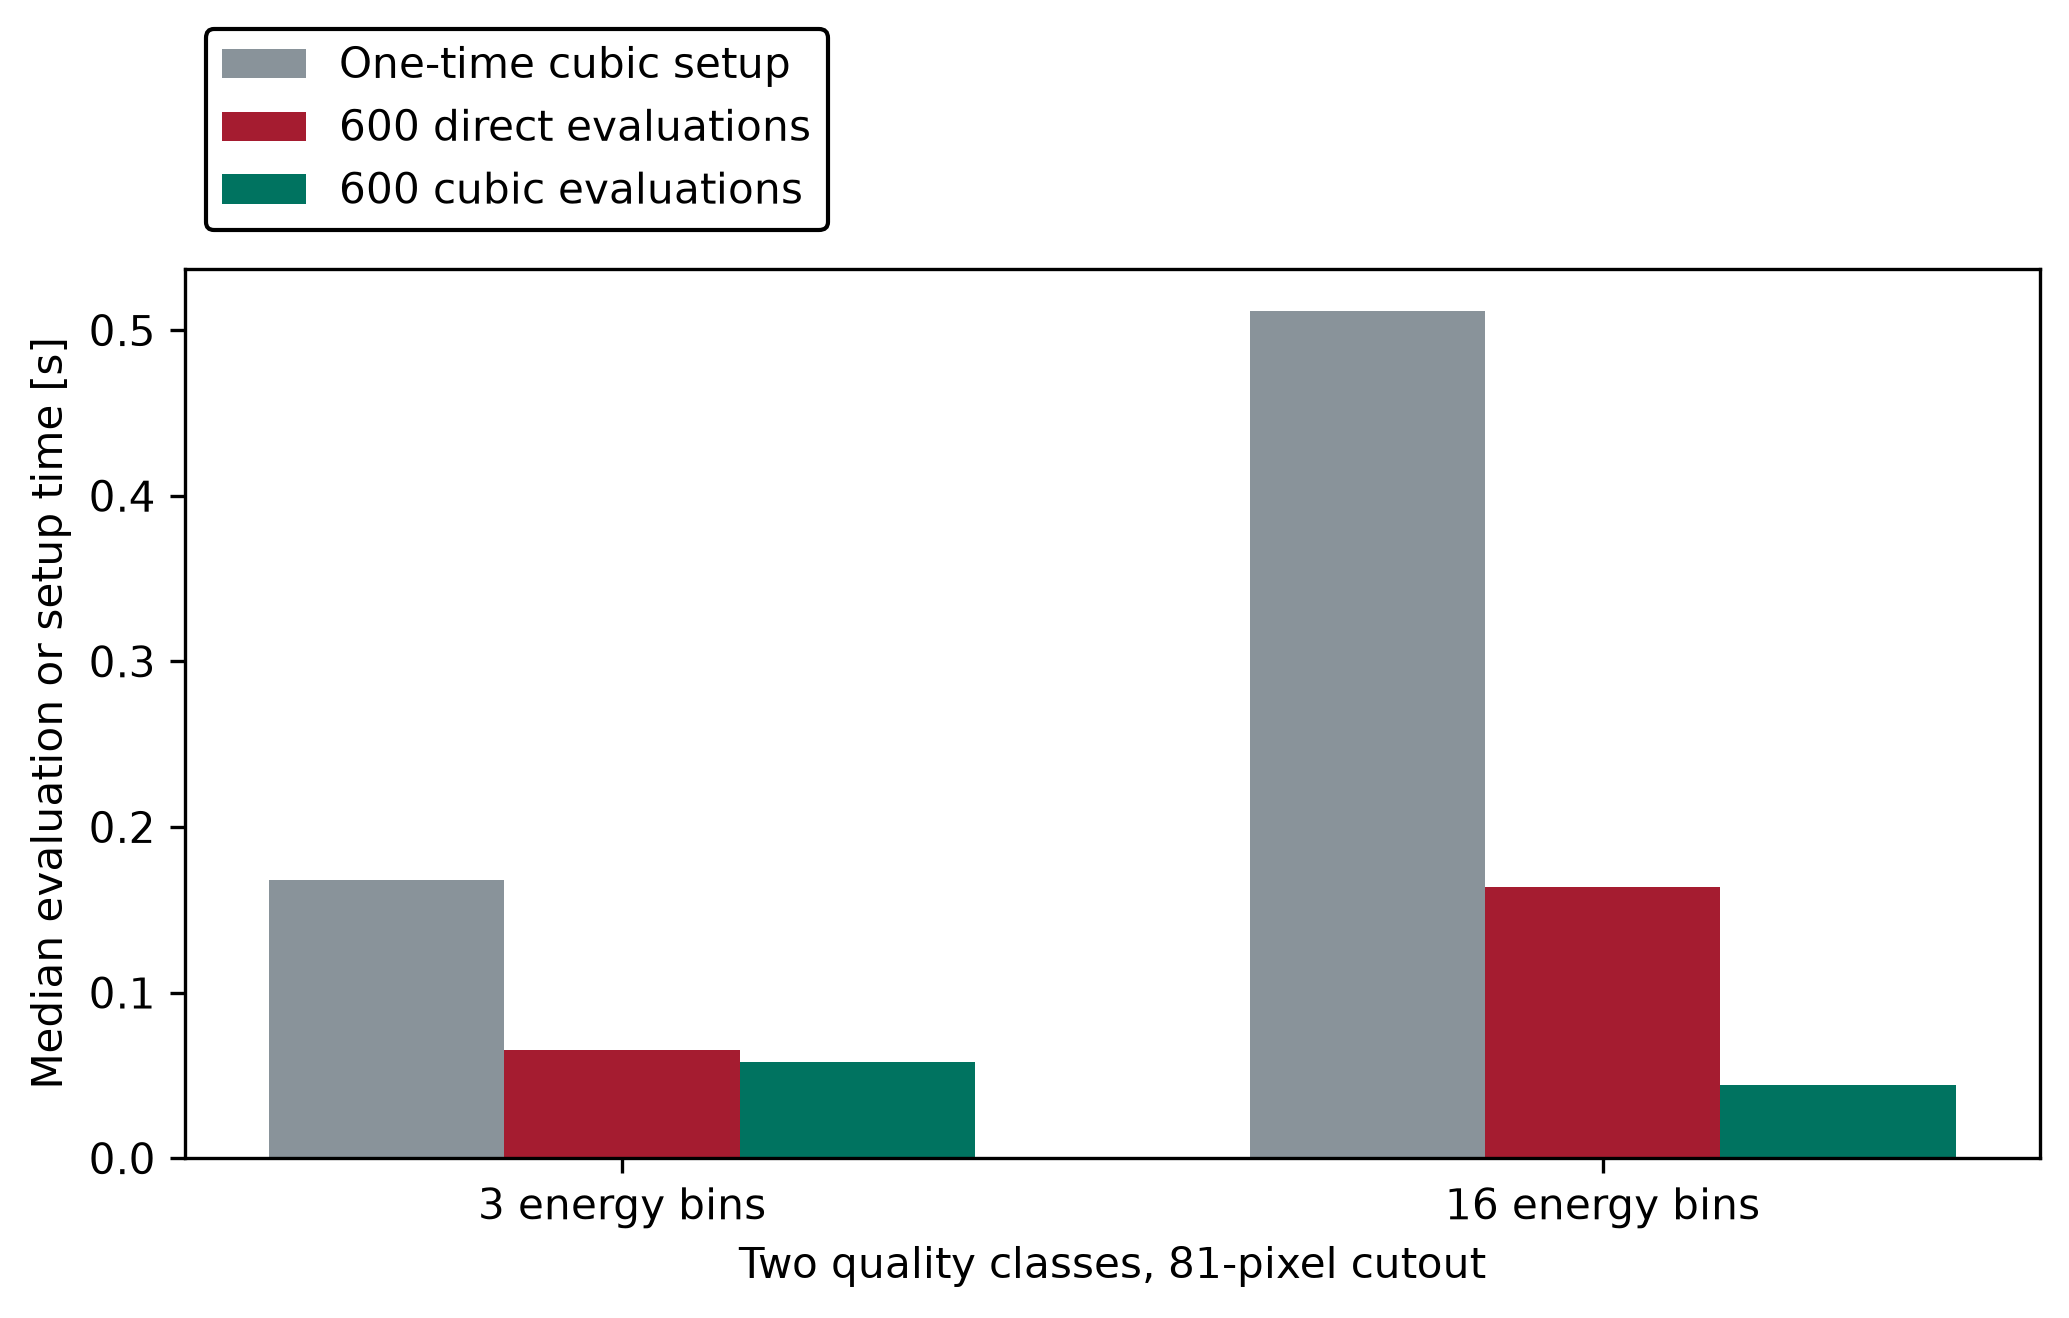

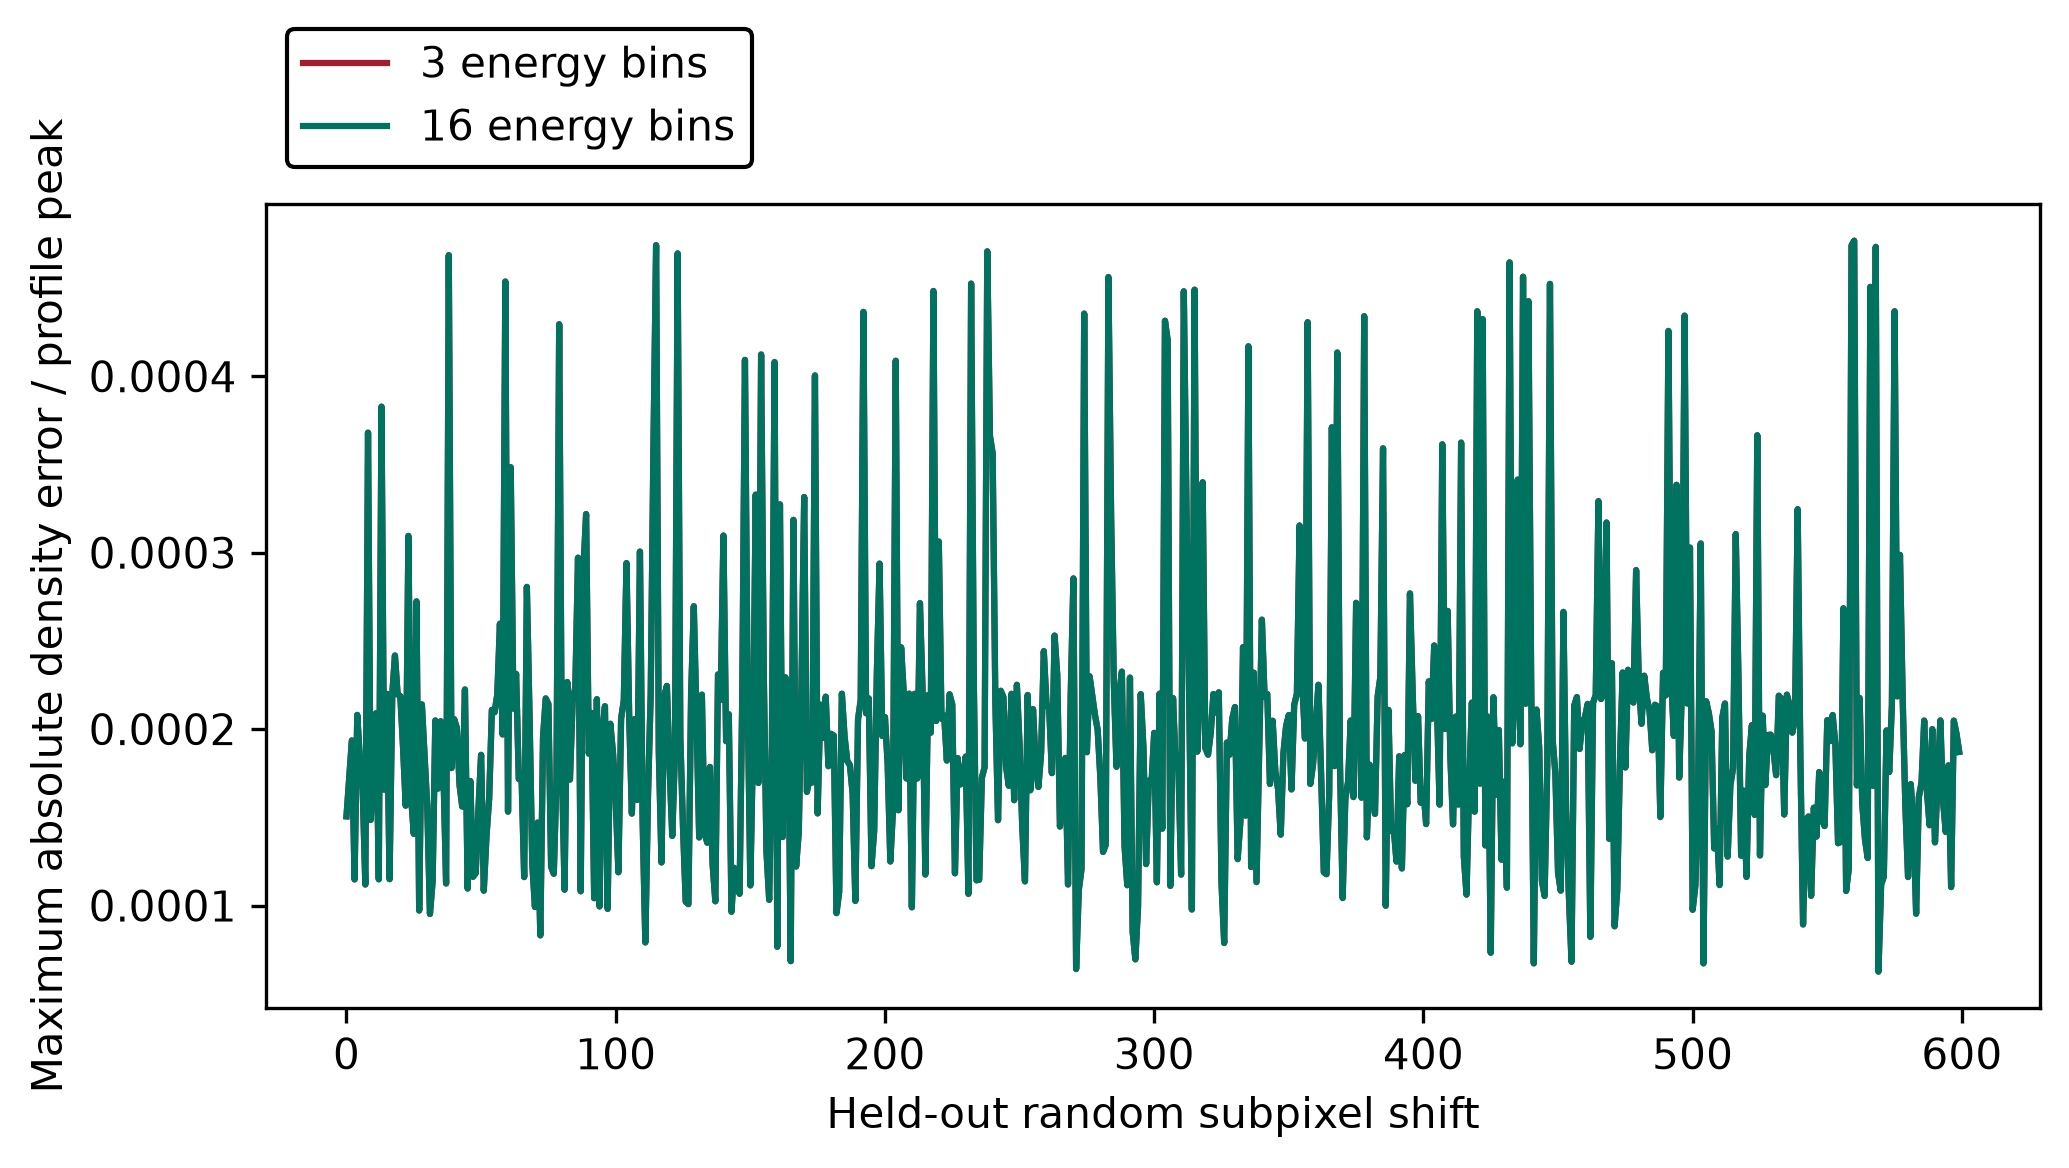

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

working_directory = Path.cwd()
candidates = [working_directory] + [
    parent / "examples" / "psf_cubic_interpolation"
    for parent in (working_directory, *working_directory.parents)
]
example_directory = next(path for path in candidates if (path / "psf_cubic_interpolation.py").is_file())
if str(example_directory) not in sys.path:
    sys.path.insert(0, str(example_directory))

from psf_cubic_interpolation import run_benchmark

result = run_benchmark(evaluations=600, repeats=3)
summary = pd.DataFrame([
    {name: value for name, value in record.items() if name != "errors_over_peak"}
    for record in result["records"]
])
display(summary.round(5))
display(Image(
    filename=str(result["timing_figure"]),
    alt="Measured cubic PSF setup cost and repeated direct and fitted evaluation times for 3 and 16 energy bins with two quality classes.",
))
display(Image(
    filename=str(result["error_figure"]),
    alt="Maximum absolute density error divided by the PSF peak over 600 held-out random subpixel shifts.",
))